# Stage 7.2 — Plausibility-filtered breach-candidate recommender and unseen-data evaluation

**Two parts.**
- **B. Breach-candidate pool.** Search outputs are collected, de-duplicated and passed through the existing validity
  and plausibility rules. Robustness is measured on **new** episode seeds, and the frozen Stage 7 recommender is
  applied. This part uses simulation only.
- **A. Unseen-data evaluation.** Frozen shortlists from three catalogs (Stage 6 library, Stage 7 extension, the
  Stage 7.2 pool) are scored against relevance labels built from **actual** market weeks:
  - **2026-01-01 onwards** is a genuine holdout, downloaded once after the protocol was frozen and hashed;
  - **2022 and 2023** are exploratory walk-forward folds (the validation split was used for selection upstream).

**Evidence labels.** HISTORICAL means actual returns. SIMULATION means frozen paths with simulated residuals; the
simulator ignores the anchor's market state, so new seeds are new noise draws, not new data. EXPLORATORY means the
period influenced earlier design decisions.

**2024–2025 is not used.** It was the Stage 8 test (consumed 2026-10-25), and the Stage 7 extension was designed after
its results were known.

Frozen and unchanged: risk engine, shock model, Stage 5 searches, Stage 6 library, Stage 7 weights / eligibility /
λ, the Stage 7 v2 output and the Stage 7 extension. Q-learning paths are **not** in the pool: re-creating them would need
retraining, which is not allowed.

In [1]:
import dataclasses
import hashlib
import json
import time
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from rlstress.config import PROJECT_ROOT, load_config, resolve_path
from rlstress.data.cleaning import clean_yahoo_frame
from rlstress.data.returns import simple_returns
from rlstress.data.storage import read_frame
from rlstress.data.yahoo_loader import download_yahoo_asset
from rlstress.final_evaluation import non_overlapping, paired_bootstrap
from rlstress.portfolio import Portfolio
from rlstress.rl.calibration import real_window_percentiles
from rlstress.rl.evaluation import evaluate_policy
from rlstress.rl.training import build_env
from rlstress.scenario_library import (FACTOR_ORDER, classify_family, cluster_features, cumulative_feature, execution_key,
                                       factor_shock_path, holding_contributions, robustness_summary, sequence_key, to_json, wilson_interval)
from rlstress.scenario_recommender import (COMPONENTS, RecommenderConfig, coverage_gaps, eligibility, exact_weight_shift, explain,
                                           library_fingerprint, portfolio_profile, scenario_features, score, select_diverse,
                                           select_random, select_top, shortlist_metrics)
from rlstress.search import GroupedActions, OpenLoopPolicy, evaluate_path, monte_carlo, monte_carlo_sequences
from rlstress.shocks import ShockModel
from rlstress.stress.historical_replay import evaluate_return_path
from rlstress.unseen_evaluation import (block_bootstrap_mean, jaccard_personalisation, match_matrix, ranking_metrics, target_weeks,
                                        week_recall)

%matplotlib inline
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 40); pd.set_option("display.max_colwidth", 100)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e4e3dc", "grid.linewidth": 0.8})

RUN_HOLDOUT = True                       # False = preflight (no 2026 data touched); True = the single holdout run
OVERWRITE = False
CFG = load_config(); SIM, TRN = CFG.simulation, CFG.training
H, K, SEED, Q = SIM.horizon_days, len(SIM.factors), SIM.seed, SIM.min_plausibility
SPLITS = CFG.data.splits.as_dict()
OUT_DIR = PROJECT_ROOT / "results" / "stage7_2"
RUN_DIR = OUT_DIR if RUN_HOLDOUT else OUT_DIR / "preflight"
REPORT_DIR = RUN_DIR / "reports"
PROTOCOL_PATH, PROTOCOL_META = OUT_DIR / "protocol.json", OUT_DIR / "protocol_meta.json"
HOLD_DIR = PROJECT_ROOT / "data" / "holdout_2026"
HOLDOUT_START, HOLDOUT_END_REQUESTED, HOLDOUT_FETCH_FROM = "2026-01-01", "2026-10-26", "2025-12-01"   # fetch from Dec 2025 for the first return only
EXPLORATORY_FOLDS = {"2022 (exploratory)": ("2022-01-01", "2022-12-31"), "2023 (exploratory)": ("2023-01-01", "2023-12-31")}
RCFG = RecommenderConfig(q=Q, top_k=5)                                     # frozen Stage 7 defaults
POOL_SCREEN_SEEDS = range(200_000, 200_200)                                 # new: pool filtering (selection)
POOL_REPORT_SEEDS = range(210_000, 210_500)                                 # new: pool eligibility and robustness score
INDEPENDENT_SEEDS = range(220_000, 220_500)                                 # new: independent evaluation of every catalog
RANDOM_SEEDS = range(SEED, SEED + 1000)                                     # random shortlists (RNG only)
PORTFOLIO_SEED, N_NEW_PORTFOLIOS = 7_000, 50                                # new random portfolios (RNG only)
N_WORST, BLOCK_DAYS, N_BOOT = 5, 20, 2000
UPSTREAM_SEEDS = {"Stage 5/6 screening": range(10_000, 10_200), "Stage 5/6 reporting": range(20_000, 20_500),
                  "Stage 5 PPO set 2 / Stage 7 fresh": range(30_000, 30_500), "Stage 5 PPO set 3": range(40_000, 40_500),
                  "Q-learning training": range(43, 45 + 20_000), "discrete MC draws": range(50_000, 50_010),
                  "DP data": range(60_000, 80_000), "Q harvest": range(70_000, 70_200), "Stage 8 test": range(90_000, 90_500)}

FROZEN = {"config/default.toml": "15924e725a64", "data/processed/features/consolidated_daily.csv": "e765acc019bb",
          "results/stage4/shock_model.json": "5fe13310b6f6", "results/stage6/scenario_library.json": "47bb6c5d3049",
          "results/stage7/recommendations.json": "045dfb911fa1", "results/stage7_extension/extended_catalog.json": "a1f94c9fd98f",
          "results/stage8/final_test_results.json": None}
sha = lambda p: hashlib.sha256((PROJECT_ROOT / p).read_bytes()).hexdigest()
SHA_BEFORE = {p: sha(p) for p in FROZEN}
for p, prefix in FROZEN.items():
    assert prefix is None or SHA_BEFORE[p].startswith(prefix), f"frozen artifact changed: {p}"
def tree_hash(root):
    h = hashlib.sha256()
    for f in sorted(p for p in (PROJECT_ROOT / root).rglob("*") if p.is_file() and "__pycache__" not in p.parts):
        h.update(str(f.relative_to(PROJECT_ROOT)).encode()); h.update(f.read_bytes())
    return h.hexdigest()
PROTECTED_TREES = ["results/stage3", "results/stage4", "results/stage5", "results/stage6", "results/stage7", "results/stage7_extension", "results/stage8"]
TREE_BEFORE = {t: tree_hash(t) for t in PROTECTED_TREES}
print(f"Mode: {'HOLDOUT RUN' if RUN_HOLDOUT else 'PREFLIGHT (2026 holdout not touched)'}; frozen artifacts verified:",
      {p: v[:12] for p, v in SHA_BEFORE.items()})

Mode: HOLDOUT RUN; frozen artifacts verified: {'config/default.toml': '15924e725a64', 'data/processed/features/consolidated_daily.csv': 'e765acc019bb', 'results/stage4/shock_model.json': '5fe13310b6f6', 'results/stage6/scenario_library.json': '47bb6c5d3049', 'results/stage7/recommendations.json': '045dfb911fa1', 'results/stage7_extension/extended_catalog.json': 'a1f94c9fd98f', 'results/stage8/final_test_results.json': '390cba05ccb0'}


## 1. Data boundaries and leakage audit

In [2]:
source = read_frame(resolve_path(CFG.risk.returns_path, PROJECT_ROOT))
model = ShockModel.from_dict(json.loads((PROJECT_ROOT / SIM.output_dir / "shock_model.json").read_text()))
library = json.loads((PROJECT_ROOT / "results/stage6/scenario_library.json").read_text())
v2 = json.loads((PROJECT_ROOT / "results/stage7/recommendations.json").read_text())
ext = json.loads((PROJECT_ROOT / "results/stage7_extension/extended_catalog.json").read_text())
s8 = json.loads((PROJECT_ROOT / "results/stage8/final_test_results.json").read_text())
meta = library["metadata"]
tickers = list(CFG.portfolio.tickers); names = [f.removesuffix("_return") for f in FACTOR_ORDER]
STOCK, FACT = [f"{t}_return" for t in tickers], list(FACTOR_ORDER)
assert tuple(model.factors) == FACTOR_ORDER
assert dataclasses.asdict(RCFG) == v2["config"], "Stage 7 recommender config differs from the frozen v2 config"
s8_time, ext_time = pd.Timestamp(s8["generated_utc"]), pd.Timestamp(ext["generated_utc"])
new_ranges = {"pool screening": POOL_SCREEN_SEEDS, "pool reporting": POOL_REPORT_SEEDS, "independent": INDEPENDENT_SEEDS}
seed_overlap = {n: sum(len(set(r) & set(u)) for u in UPSTREAM_SEEDS.values()) for n, r in new_ranges.items()}
seed_overlap["new ranges among themselves"] = len(set(POOL_SCREEN_SEEDS) & set(POOL_REPORT_SEEDS)) + len(set(POOL_REPORT_SEEDS) & set(INDEPENDENT_SEEDS)) + len(set(POOL_SCREEN_SEEDS) & set(INDEPENDENT_SEEDS))
assert not any(seed_overlap.values()), seed_overlap
data_last = source.index.max()
audit = pd.DataFrame([
    ("Shock model fit, plausibility calibration (q)", f"train {SPLITS['train'][0]} – {SPLITS['train'][1]} (actual returns)", "—", "clean"),
    ("Plausibility threshold selection", "validation actual weeks (rejection share; default q kept on a tie)", "—", "validation used for selection"),
    ("Stage 5 Monte Carlo / Q-learning search", "train anchors; simulated residuals", "50000–50009, 43–20044, 60000–79999, 70000–70199", "clean (simulation)"),
    ("PPO checkpoint selection", "validation anchors (state-dependent policy)", "10000–10199", "validation used for selection"),
    ("Stage 6 screening / reporting", "validation anchors; simulation is anchor-independent", "10000–10199 / 20000–20499", "simulation only"),
    ("Stage 7 v2 weights, eligibility, λ", "declared defaults, not tuned; simulation evidence", "20000–20499, 30000–30499", "clean"),
    ("Stage 8 final test", f"test {SPLITS['test'][0]} – {SPLITS['test'][1]} actual returns; run {s8_time.date()}", "90000–90499", "TEST CONSUMED"),
    ("Stage 7 extension", f"designed {ext_time.date()}, after Stage 8 results were known", "10000–10199, 20000–20499, 30000–30499",
     "2024–25 NOT clean for it" if ext_time > s8_time else "check"),
    ("Stage 7.2 pool robustness / independent evaluation", "simulation (new noise draws, not new data)", "200000–200199, 210000–210499, 220000–220499", "new seeds, disjoint"),
    ("Stage 7.2 exploratory folds", "2022, 2023 actual returns (validation split)", "—", "EXPLORATORY"),
    ("Stage 7.2 holdout", f"{HOLDOUT_START} → {HOLDOUT_END_REQUESTED} actual returns; project data ends {data_last.date()}", "—",
     "UNSEEN (downloaded once, after the protocol freeze)"),
    ("2024–2025", "Stage 8 test split", "—", "NOT USED in Stage 7.2"),
], columns=["step", "data / period", "episode seeds", "status"])
display(audit.style.hide(axis="index").set_caption("Data boundaries and leakage audit"))
assert data_last == pd.Timestamp(SPLITS["test"][1]) and pd.Timestamp(HOLDOUT_START) > data_last
assert ext_time > s8_time, "expected the extension to post-date Stage 8 (it is treated as contaminated for 2024-25)"
print("New seed ranges overlap upstream use:", seed_overlap)

step,data / period,episode seeds,status
"Shock model fit, plausibility calibration (q)",train 2015-01-01 – 2021-12-31 (actual returns),—,clean
Plausibility threshold selection,validation actual weeks (rejection share; default q kept on a tie),—,validation used for selection
Stage 5 Monte Carlo / Q-learning search,train anchors; simulated residuals,"50000–50009, 43–20044, 60000–79999, 70000–70199",clean (simulation)
PPO checkpoint selection,validation anchors (state-dependent policy),10000–10199,validation used for selection
Stage 6 screening / reporting,validation anchors; simulation is anchor-independent,10000–10199 / 20000–20499,simulation only
"Stage 7 v2 weights, eligibility, λ","declared defaults, not tuned; simulation evidence","20000–20499, 30000–30499",clean
Stage 8 final test,test 2024-01-01 – 2025-12-31 actual returns; run 2026-10-24,90000–90499,TEST CONSUMED
Stage 7 extension,"designed 2026-10-27, after Stage 8 results were known","10000–10199, 20000–20499, 30000–30499",2024–25 NOT clean for it
Stage 7.2 pool robustness / independent evaluation,"simulation (new noise draws, not new data)","200000–200199, 210000–210499, 220000–220499","new seeds, disjoint"
Stage 7.2 exploratory folds,"2022, 2023 actual returns (validation split)",—,EXPLORATORY


New seed ranges overlap upstream use: {'pool screening': 0, 'pool reporting': 0, 'independent': 0, 'new ranges among themselves': 0}


## 2. (B) Candidate collection
**Sources:**
- the continuous and discrete Monte Carlo searches, re-run exactly as Stage 6 ran them (same seeds; the reproduction is checked);
- the 16 Stage 6 library paths;
- the Stage 7 extension variants, regenerated with the recorded transform settings.

**Discovery settings:** every candidate was discovered on the default portfolio, with training anchors or a deterministic replay.

In [3]:
t0 = time.perf_counter()
cfg_mean = dataclasses.replace(CFG, simulation=dataclasses.replace(SIM, residual_mode="mean"))
search_env = build_env(cfg_mean, source, model, Q, "train")               # deterministic, training anchors (as Stage 6)
train_env = build_env(CFG, source, model, Q, "train")                     # sampled residuals, training anchors (discrete MC draws)
eval_env = build_env(CFG, source, model, Q, "validation")                 # sampled residuals, validation anchors (robustness)
SEARCH_ANCHOR = search_env.market_states.index[len(search_env.market_states) // 2]
OBS = {n: i for i, n in enumerate(search_env.observation_names)}
BOUNDS = search_env.simulator.bounds
assert np.allclose(BOUNDS, [meta["factor_bounds"][n] for n in names])
evaluate = lambda x: evaluate_path(search_env, np.asarray(x, dtype=float).reshape(H, K), SEARCH_ANCHOR, SEED)
ACTS = GroupedActions(abs(TRN.scripted_action), k=K)

mc = monte_carlo(evaluate, H * K, 6000, seed=SEED + 2)                                    # Stage 6 "Monte Carlo (original)"
mcd = monte_carlo_sequences(train_env, ACTS, 79_738, 10, 50_000, SEED + 4, 0.80)          # Stage 6 "Monte Carlo (discrete)"; budget = recorded Q steps
mc_repro = {"continuous breaches": sum(r["breached"] for r in mc["records"]), "continuous valid": sum(r["valid"] for r in mc["records"]),
            "discrete sequences": len(mcd["candidates"]), "discrete steps": mcd["steps"]}
print("Reproduction of the Stage 5/6 searches:", mc_repro, f"({time.perf_counter() - t0:.0f}s)")
assert mc_repro == {"continuous breaches": 2027, "continuous valid": 0, "discrete sequences": 1754, "discrete steps": 79_748}

ext_method = ext["method"]
def variants(A):
    order = np.argsort(A.sum(axis=1))
    out = {f"intensity x{c:.2f}": A * c for c in ext_method["intensity_scales"]}
    out.update({"reversed days": A[::-1], "front-loaded": A[order], "back-loaded": A[order[::-1]]})
    out.update({n: A * np.array(m) for n, m in ext_method["factor_tilts"].items()})
    return {k: np.clip(v, -1.0, 1.0) for k, v in out.items()}

rows, paths = [], {}
def add(src, kind, path, parent="", seeds="", period=""):
    path = np.round(np.asarray(path, dtype=float).reshape(H, K), 6)
    k = sequence_key(path)
    paths.setdefault(k, path)
    rows.append({"source": src, "kind": kind, "seq_key": k, "parent": parent, "discovery portfolio": "default (equal weight)",
                 "discovery seeds": seeds, "discovery data": period})
TRAIN_ANCHORS = f"train anchors {SPLITS['train'][0]}–{SPLITS['train'][1]}"
for r in mc["records"]:
    add("Monte Carlo (continuous)", "search output", r["A"], seeds=f"uniform RNG {SEED + 2}; deterministic replay", period=f"deterministic, anchor {SEARCH_ANCHOR.date()}")
for seq in mcd["candidates"]["sequence"]:
    add("Monte Carlo (discrete)", "search output", ACTS.actions[list(seq)], seeds=f"RNG {SEED + 4}; draws 50000–50009", period=TRAIN_ANCHORS)
for s in library["scenarios"]:
    add("Stage 6 library", "library representative", s["robust_action_path"], parent=s["scenario_id"], seeds="Stage 6", period="Stage 6 (validation anchors)")
for s in library["scenarios"]:
    for vname, P in variants(np.asarray(s["robust_action_path"], dtype=float)).items():
        add("Stage 7 extension variant", f"variant: {vname}", P, parent=s["scenario_id"], seeds="none (transform)", period="transform of a Stage 6 path")
cand = pd.DataFrame(rows)
ext_keys = {sequence_key(np.round(np.asarray(s["robust_action_path"], dtype=float), 6)) for s in ext["catalog"]}
assert ext_keys <= set(paths), "extension catalog paths are not all regenerated"
display(cand.groupby("source").agg(candidates=("seq_key", "size"), unique_paths=("seq_key", "nunique")).style.set_caption("Collected candidates"))

Reproduction of the Stage 5/6 searches: {'continuous breaches': 2027, 'continuous valid': 0, 'discrete sequences': 1754, 'discrete steps': 79748} (249s)


,candidates,unique_paths
source,,
Monte Carlo (continuous),6000,6000
Monte Carlo (discrete),1754,1736
Stage 6 library,16,16
Stage 7 extension variant,240,240


## 3. (B) Validity, plausibility and de-duplication
**Filters, in order:**
1. Simulator failures are labelled **unverified**.
2. Paths that do not breach a limit are removed.
3. Breaches with rank < q are **implausible**. This is the existing Stage 4 historical path percentile, calibrated on train.
4. Exact duplicates of the executed path are merged.
5. Near-duplicates (distance ≤ 0.335, the Stage 6 one-step cut) are merged.

**Representative of a merged group, by priority:** Stage 6 library path > search output > extension variant; then
the highest rank. Variants of the same parent are counted as variants, not as independent evidence.

In [4]:
t0 = time.perf_counter()
det = {k: evaluate(p) for k, p in paths.items()}
dd_limit = next(l.threshold for l in CFG.risk.limits if l.metric == "max_drawdown" and l.horizon_days == H)
loss_limit = next(l.threshold for l in CFG.risk.limits if l.metric == "cumulative_loss" and l.horizon_days == H)
def det_fields(k):
    r = det[k]
    status = ("unverified (simulator failure)" if r["invalid"] else "no breach" if not r["breached"] else
              "unverified (rank undefined)" if not np.isfinite(r["rank"]) else "implausible breach" if r["rank"] < Q else "plausible breach")
    limit = ("" if not r["breached"] else "stress_drawdown_5d" if r["drawdown"] >= dd_limit - 1e-12 else "stress_loss_5d")
    return {"status": status, "days": r["days"], "rank": r["rank"], "drawdown": r["drawdown"], "loss": r["loss"], "limit breached": limit,
            "exec_key": execution_key(paths[k], r["days"]) if r["days"] else ""}
cand = cand.join(pd.DataFrame([det_fields(k) for k in cand["seq_key"]], index=cand.index))
assert ((cand["status"] == "plausible breach") == cand["seq_key"].map(lambda k: bool(det[k]["valid"]))).all(), "plausibility rule differs from the environment"
PRIORITY = {"Stage 6 library": 0, "Monte Carlo (discrete)": 1, "Monte Carlo (continuous)": 1, "Stage 7 extension variant": 2}
uniq = (cand.assign(prio=cand["source"].map(PRIORITY)).sort_values(["prio", "source", "seq_key"])
            .groupby("exec_key", sort=False).agg(seq_key=("seq_key", "first"), source=("source", "first"), parent=("parent", "first"),
                                                 kind=("kind", "first"), sources=("source", lambda s: "; ".join(sorted(set(s)))),
                                                 status=("status", "first"), days=("days", "first"), rank=("rank", "first"),
                                                 drawdown=("drawdown", "first"), loss=("loss", "first"), limit_breached=("limit breached", "first"),
                                                 discovery_seeds=("discovery seeds", "first"), discovery_data=("discovery data", "first"))
            .reset_index())
uniq = uniq[uniq["exec_key"] != ""]
plaus = uniq[uniq["status"] == "plausible breach"].reset_index(drop=True)
plaus["family"] = [classify_family(paths[k][:d], meta["family_rules"]["delta"]) for k, d in zip(plaus["seq_key"], plaus["days"])]
FEAT = {k: cumulative_feature(paths[k], d) for k, d in zip(plaus["seq_key"], plaus["days"])}
plaus["near_dup_group"] = cluster_features(np.vstack([FEAT[k] for k in plaus["seq_key"]]), meta["clustering"]["near_duplicate_cut"])
plaus["prio"] = plaus["source"].map(PRIORITY)
reps = []
for g, members in plaus.groupby("near_dup_group"):
    lib = members[members["source"] == "Stage 6 library"]
    keep = lib if len(lib) else members.sort_values(["prio", "rank", "drawdown", "seq_key"], ascending=[True, False, False, True]).head(1)
    reps.append(keep.assign(group_size=len(members), group_sources="; ".join(sorted(set("; ".join(members["sources"]).split("; "))))))
reps = pd.concat(reps).reset_index(drop=True)
LIB_KEY = {sequence_key(np.round(np.asarray(s["robust_action_path"], dtype=float), 6)): s["scenario_id"] for s in library["scenarios"]}
EXT_ID = {sequence_key(np.round(np.asarray(s["robust_action_path"], dtype=float), 6)): s["scenario_id"] for s in ext["catalog"]}
reps["scenario_id"] = [LIB_KEY.get(k) or EXT_ID.get(k) or "S72-" + hashlib.sha1(k.encode()).hexdigest()[:8] for k in reps["seq_key"]]
assert reps["scenario_id"].is_unique and reps["seq_key"].is_unique
funnel_rows = []
for src in ["Monte Carlo (continuous)", "Monte Carlo (discrete)", "Stage 6 library", "Stage 7 extension variant", "all sources"]:
    c = cand if src == "all sources" else cand[cand["source"] == src]
    funnel_rows.append({"source": src, "collected": len(c), "unique paths": c["seq_key"].nunique(), "unverified": int(c["status"].str.startswith("unverified").sum()),
                        "breaching (unique executed)": c.loc[c["status"].isin(["plausible breach", "implausible breach"]), "exec_key"].nunique(),
                        "implausible (unique executed)": c.loc[c["status"] == "implausible breach", "exec_key"].nunique(),
                        "plausible (unique executed)": c.loc[c["status"] == "plausible breach", "exec_key"].nunique()})
funnel = pd.DataFrame(funnel_rows).set_index("source")
funnel.loc["all sources", "near-duplicate groups (representatives)"] = len(reps)
display(funnel.style.format("{:,.0f}", na_rep="—").set_caption("Filtering funnel (unique executed paths; sources overlap, so rows do not add up)"))
display(reps.groupby(["family", "source"]).size().unstack(fill_value=0).style.set_caption("Representatives by family and representative source"))
print(f"{len(cand):,} collected → {cand['seq_key'].nunique():,} unique paths → {len(uniq):,} unique executed → {len(plaus):,} plausible breaches "
      f"→ {len(reps)} near-duplicate representatives ({time.perf_counter() - t0:.0f}s)")

,collected,unique paths,unverified,breaching (unique executed),implausible (unique executed),plausible (unique executed),near-duplicate groups (representatives)
source,,,,,,,
Monte Carlo (continuous),"6,000","6,000",0,"2,027","2,027",0,—
Monte Carlo (discrete),"1,754","1,736",0,963,402,561,—
Stage 6 library,16,16,0,16,0,16,—
Stage 7 extension variant,240,240,0,193,40,153,—
all sources,"8,010","7,973",0,"3,170","2,464",706,340


source,Monte Carlo (discrete),Stage 6 library,Stage 7 extension variant
family,,,
broad-market,193,12,27
energy-led,0,0,5
financial-led,0,0,5
sector-led (financials and energy jointly),83,4,4
technology-led,0,0,7


8,010 collected → 7,973 unique paths → 7,795 unique executed → 706 plausible breaches → 340 near-duplicate representatives (83s)


## 4. (B) Robustness on new episodes, eligibility, frozen ranking
The Stage 6 protocol is reused with **new** seeds:
- screening on 200000–200199 decides **validated**;
- reporting on 210000–210499 gives P(valid) for eligibility and the robustness score;
- an independent evaluation on 220000–220499 (section 6) is never used for selection.

Eligibility, weights and λ are the frozen Stage 7 values.

In [5]:
t0 = time.perf_counter()
pool = []
for r in reps.itertuples():
    P = paths[r.seq_key]
    pol = OpenLoopPolicy(P, OBS, r.scenario_id)
    scr = robustness_summary(evaluate_policy(eval_env, pol, POOL_SCREEN_SEEDS))
    validated = scr["p_valid"] >= meta["selection_rule"]["p_valid_target"]
    rep = robustness_summary(evaluate_policy(eval_env, pol, POOL_REPORT_SEEDS)) if validated else None
    ex = P[: r.days]
    pool.append({"scenario_id": r.scenario_id, "status": "validated" if validated else "exploratory", "family": r.family,
                 "discovery_methods": r.group_sources.split("; "), "representative_candidate_id": r.scenario_id, "executed_days": int(r.days),
                 "action_path": ex.tolist(), "factor_shock_path": factor_shock_path(ex, BOUNDS).tolist(), "robust_action_path": P.tolist(),
                 "deterministic_rank": float(r.rank), "deterministic_drawdown": float(r.drawdown), "deterministic_breach_day": int(r.days),
                 "limit_breached": r.limit_breached, "p_valid": rep["p_valid"] if rep else None, "p_valid_ci95": rep["p_valid_ci95"] if rep else None,
                 "p_any_breach": rep["p_any_breach"] if rep else None, "p_implausible": rep["p_implausible"] if rep else None,
                 "mean_drawdown_at_breach": rep["mean_drawdown_at_breach"] if rep else None, "mean_breach_day": rep["mean_breach_day"] if rep else None,
                 "screening_p_valid": scr["p_valid"], "screening_episodes": scr["episodes"], "reporting_episodes": rep["episodes"] if rep else 0,
                 "plausibility_method": "Stage 4 historical path percentile (Fisher-combined factor tail probability vs train windows)",
                 "provenance": {"representative_source": r.source, "parent": r.parent, "kind": r.kind, "group_size": int(r.group_size),
                                "group_sources": r.group_sources, "discovery_portfolio": "default (equal weight)", "discovery_seeds": r.discovery_seeds,
                                "discovery_data": r.discovery_data, "screening_seeds": [POOL_SCREEN_SEEDS.start, POOL_SCREEN_SEEDS.stop - 1],
                                "reporting_seeds": [POOL_REPORT_SEEDS.start, POOL_REPORT_SEEDS.stop - 1], "anchors": "validation split"},
                 "sequence_key": r.seq_key})
pool_runtime = time.perf_counter() - t0
for s, cl in zip(pool, cluster_features(np.vstack([FEAT[s["sequence_key"]] for s in pool]), meta["clustering"]["cluster_cut"])):
    s["cluster"] = int(cl)
CAT = {}                                       # catalog name -> {"features": eligibility frame, "by_id": scenario dicts, "key": id -> sequence key}
def register(name, scenarios):
    f = eligibility(scenario_features({"metadata": meta, "scenarios": scenarios}, model.factor_sd, H), RCFG)
    CAT[name] = {"features": f, "by_id": {s["scenario_id"]: s for s in scenarios},
                 "key": {s["scenario_id"]: sequence_key(np.round(np.asarray(s["robust_action_path"], dtype=float), 6)) for s in scenarios}}
register("Stage 6 library", library["scenarios"])
register("Stage 7 extension", [{k: v for k, v in s.items() if k not in ("eligible", "ineligible_reason")} for s in ext["catalog"]])
register("Stage 7.2 pool", pool)
assert int(CAT["Stage 6 library"]["features"]["eligible"].sum()) == 8
ext_flags = {s["scenario_id"]: s["eligible"] for s in ext["catalog"]}
assert all(ext_flags[r.scenario_id] == r.eligible for r in CAT["Stage 7 extension"]["features"].itertuples()), "extension eligibility not reproduced"
sizes = pd.DataFrame({n: {"scenarios": len(c["features"]), "validated": int((c["features"]["status"] == "validated").sum()),
                          "eligible": int(c["features"]["eligible"].sum()), "eligible families": c["features"].loc[c["features"]["eligible"], "family"].nunique(),
                          "eligible clusters": c["features"].loc[c["features"]["eligible"], "cluster"].nunique()} for n, c in CAT.items()})
display(sizes.style.set_caption(f"Catalogs (pool robustness {pool_runtime:.0f}s)"))
display(pd.DataFrame({n: c["features"].loc[c["features"]["eligible"], "family"].value_counts() for n, c in CAT.items()}).fillna(0).astype(int)
        .style.set_caption("Eligible scenarios by family"))

,Stage 6 library,Stage 7 extension,Stage 7.2 pool
scenarios,16,82,340
validated,8,35,199
eligible,8,34,195
eligible families,2,5,5
eligible clusters,8,15,22


,Stage 6 library,Stage 7 extension,Stage 7.2 pool
family,,,
broad-market,7,27,144
energy-led,0,1,1
financial-led,0,1,1
sector-led (financials and energy jointly),1,3,48
technology-led,0,2,1


## 5. Portfolios, scores and frozen shortlists
**Portfolios:** the 4 Stage 7 profiles plus 50 **new** random long-only portfolios (Dirichlet(1), RNG seed 7000; Stage 7's
extension used seed 5000). Impact is the frozen deterministic replay for each portfolio.

**Recommenders** are identical across catalogs and use k = 5:
- the frozen diversity-aware ranking and the highest composite score;
- single-signal rankings by robustness, severity, relevance or plausibility;
- random, averaged over 1,000 seeds.

**Relevance-only caveat:** this recommender ranks by the model-implied cosine to the portfolio's loss direction. That
signal is part of the composite score, so it is **not** an independent relevance measure.

In [6]:
sectors = {a.alias: a.sector for a in CFG.data.enabled_assets("stock")}
train_returns = source.loc[SPLITS["train"][0]:SPLITS["train"][1], STOCK].rename(columns=lambda c: c.removesuffix("_return"))
PORTFOLIOS = {
    "default (equal weight)": np.array(CFG.portfolio.weights, dtype=float),
    "hypothetical: technology-heavy": np.array([0.25, 0.25, 0.25, 0.05, 0.05, 0.05, 0.05, 0.05]),
    "hypothetical: financials and energy-heavy": np.array([0.05, 0.05, 0.05, 0.30, 0.30, 0.05, 0.05, 0.15]),
    "hypothetical: defensive": np.array([0.05, 0.10, 0.05, 0.10, 0.10, 0.30, 0.25, 0.05]),
}
assert np.allclose(PORTFOLIOS["default (equal weight)"], [v2["portfolio_profiles"]["default (equal weight)"]["weights"][t] for t in tickers])
for i, w in enumerate(np.random.default_rng(PORTFOLIO_SEED).dirichlet(np.ones(len(tickers)), size=N_NEW_PORTFOLIOS)):
    PORTFOLIOS[f"new random portfolio {i:02d}"] = w / w.sum()
DEFAULT = "default (equal weight)"
PROFILE = {n: portfolio_profile(n, tickers, w, CFG.portfolio.initial_capital, model.raw_loadings, model.factor_sd, sectors, train_returns, dd_limit)
           for n, w in PORTFOLIOS.items()}

ELIG_KEYS = sorted({c["key"][i] for c in CAT.values() for i in c["features"].loc[c["features"]["eligible"], "scenario_id"]})
t0 = time.perf_counter()
IMPACT = {}                                    # portfolio -> sequence key -> replayed drawdown
for pname, w in PORTFOLIOS.items():
    pcfg = dataclasses.replace(cfg_mean, portfolio=dataclasses.replace(CFG.portfolio, weights=tuple(float(x) for x in w)))
    env = build_env(pcfg, source, model, Q, "train")
    anchor = env.market_states.index[len(env.market_states) // 2]
    IMPACT[pname] = {k: float(evaluate_path(env, paths[k], anchor, SEED)["drawdown"]) for k in ELIG_KEYS}   # full robust path, as Stage 7
impact_runtime = time.perf_counter() - t0
v2_imp = {r["scenario_id"]: r["portfolio_drawdown"] for r in v2["recommendations"]}
impact_repro = max(abs(IMPACT[DEFAULT][CAT["Stage 6 library"]["key"][i]] - d) for i, d in v2_imp.items())
assert impact_repro < 1e-9, f"replay does not reproduce the frozen Stage 7 impacts ({impact_repro})"

def select_by(Sx, col, k):
    return list(Sx[Sx["eligible"]].sort_values([col, "scenario_id"], ascending=[False, True])["scenario_id"].head(k))
RECOMMENDERS = {
    "diversity-aware (frozen Stage 7)": lambda Sx: [d["scenario_id"] for d in select_diverse(Sx, RCFG.top_k, RCFG)],
    "highest score": lambda Sx: select_top(Sx, RCFG.top_k),
    "robustness only": lambda Sx: select_by(Sx, "robustness", RCFG.top_k),
    "severity only": lambda Sx: select_by(Sx, "portfolio_drawdown", RCFG.top_k),
    "relevance only (model cosine; not independent)": lambda Sx: select_by(Sx, "relevance", RCFG.top_k),
    "plausibility only": lambda Sx: select_by(Sx, "plausibility", RCFG.top_k),
}
SCORED, SHORT, RANDOM = {}, {}, {}
for cname, c in CAT.items():
    SCORED[cname], SHORT[cname], RANDOM[cname] = {}, {r: {} for r in RECOMMENDERS}, {}
    for pname in PORTFOLIOS:
        imp = {i: IMPACT[pname][c["key"][i]] for i in c["features"].loc[c["features"]["eligible"], "scenario_id"]}
        Sx = score(c["features"], PROFILE[pname], imp, RCFG)
        SCORED[cname][pname] = Sx
        for rname, fn in RECOMMENDERS.items():
            SHORT[cname][rname][pname] = fn(Sx)
        RANDOM[cname][pname] = [select_random(Sx, RCFG.top_k, s) for s in RANDOM_SEEDS]
assert SHORT["Stage 6 library"]["diversity-aware (frozen Stage 7)"][DEFAULT] == [d["scenario_id"] for d in v2["shortlists"]["diversity_aware"]]
assert SHORT["Stage 6 library"]["highest score"][DEFAULT] == v2["shortlists"]["highest_score"]
assert all(len(l) == RCFG.top_k for c in SHORT.values() for r in c.values() for l in r.values())
print(f"Scored {len(CAT)} catalogs x {len(PORTFOLIOS)} portfolios ({len(ELIG_KEYS)} unique eligible paths, impacts in {impact_runtime:.0f}s); "
      f"frozen Stage 7 v2 shortlists and impacts reproduced (max |diff| {impact_repro:.1e})")
for cname in CAT:
    print(f"{cname:22s} default, diversity-aware: {SHORT[cname]['diversity-aware (frozen Stage 7)'][DEFAULT]}")

Scored 3 catalogs x 54 portfolios (205 unique eligible paths, impacts in 109s); frozen Stage 7 v2 shortlists and impacts reproduced (max |diff| 0.0e+00)
Stage 6 library        default, diversity-aware: ['S6-cb7bea96', 'S6-0b517d5c', 'S6-b0972d80', 'S6-b13030ae', 'S6-57e21a76']
Stage 7 extension      default, diversity-aware: ['S7X-a312a53e', 'S7X-6bea5299', 'S7X-cd64df2f', 'S7X-c63e8646', 'S6-cb7bea96']
Stage 7.2 pool         default, diversity-aware: ['S72-e535bb64', 'S72-ba628b15', 'S7X-6bea5299', 'S72-0a4eb03b', 'S72-2369c904']


In [7]:
# Top-k of the Stage 7.2 pool for the default portfolio, with explanations (frozen Stage 7 explain())
pS = SCORED["Stage 7.2 pool"][DEFAULT].set_index("scenario_id", drop=False)
div = select_diverse(SCORED["Stage 7.2 pool"][DEFAULT], RCFG.top_k, RCFG)
TOPK_OUTPUT = []
for i, d in enumerate(div, 1):
    row = pS.loc[d["scenario_id"]]
    rec = evaluate(np.asarray(row["padded_action_path"]))
    hc = holding_contributions(np.array(rec["stock_returns"]), PORTFOLIOS[DEFAULT], CFG.portfolio.initial_capital, tickers)
    s = CAT["Stage 7.2 pool"]["by_id"][d["scenario_id"]]
    TOPK_OUTPUT.append({"rank": i, "scenario_id": d["scenario_id"], "score": d["score"], "adjusted_score": d["adjusted_score"],
                        "family": row["family"], "cluster": int(row["cluster"]), "executed_days": int(row["executed_days"]),
                        "robust_action_path": s["robust_action_path"], "portfolio_drawdown": row["portfolio_drawdown"],
                        "limit_breached": s["limit_breached"], "rank_plausibility": row["rank"], "p_valid_reporting": row["p_valid"],
                        "components": {c: row[c] for c in COMPONENTS}, "provenance": s["provenance"],
                        "explanation": explain(row, PROFILE[DEFAULT], [pS.loc[x["scenario_id"]] for x in div[: i - 1]], RCFG, dict(zip(hc["ticker"], hc["pnl"])))})
for r in TOPK_OUTPUT:
    print(f"#{r['rank']} {r['scenario_id']} score {r['score']:.3f} (adjusted {r['adjusted_score']:.3f}); source {r['provenance']['representative_source']}"
          f" (group of {r['provenance']['group_size']}: {r['provenance']['group_sources']})\n   {r['explanation']}\n")
stab = []
base_ids = [d["scenario_id"] for d in div]
for comp in COMPONENTS:
    for delta in (-0.05, 0.05):
        cfg = dataclasses.replace(RCFG, weights=exact_weight_shift(RCFG.weights, comp, delta))
        ids = [d["scenario_id"] for d in select_diverse(score(CAT["Stage 7.2 pool"]["features"], PROFILE[DEFAULT],
               {i: IMPACT[DEFAULT][CAT["Stage 7.2 pool"]["key"][i]] for i in pS.loc[pS["eligible"], "scenario_id"]}, cfg), RCFG.top_k, cfg)]
        stab.append({"perturbation": f"{comp} {delta:+.2f}", "jaccard vs frozen": len(set(ids) & set(base_ids)) / len(set(ids) | set(base_ids)), "same order": ids == base_ids})
stability = pd.DataFrame(stab)
display(stability.style.hide(axis="index").format({"jaccard vs frozen": "{:.2f}"}).set_caption("Pool shortlist stability under ±0.05 weight shifts (descriptive; weights are not re-tuned)"))

#1 S72-e535bb64 score 0.785 (adjusted 0.785); source Monte Carlo (discrete) (group of 3: Monte Carlo (discrete))
   broad-market scenario over 5 day(s); largest cumulative shock on SPY (-12.6 model sd; cumulative factor returns SPY -12.7%, QQQ -15.8%, XLF -12.2%, XLE -16.6%). Relevance 0.98: alignment with this portfolio's loss direction (largest sensitivity SPY). Impact: replayed path drawdown 14.07% for 'default (equal weight)' (limit 10%). Largest holding losses: NVDA -2,941, AAPL -2,231, MSFT -2,105. Evidence: rank 0.0216 (q = 0.01); P(valid) 100.0% [99.2%, 100.0%] on 500 reporting episodes; P(implausible) 0.0%; screening P(valid) 99.0% on 200. Limitations: fixed five-day path replayed in the Stage 4 model (i.i.d. daily shocks, tails lighter than history); robustness from Stage 6 reporting episodes (validation-period residual draws, separate from the screening episodes Stage 6 used for selection); not a test-period result.

#2 S72-ba628b15 score 0.732 (adjusted 0.686); source Monte

perturbation,jaccard vs frozen,same order
relevance -0.05,1.00,True
relevance +0.05,0.67,False
impact -0.05,0.25,False
impact +0.05,0.67,False
plausibility -0.05,0.67,False
plausibility +0.05,0.25,False
robustness -0.05,1.00,True
robustness +0.05,0.67,False


## 6. (SIMULATION) Independent evaluation on new episodes
Every eligible path of every catalog is replayed open loop on the same 500 new seeds (220000–220499), which gives common
random numbers across catalogs. These seeds were used by **no** selection step. Because the dynamics ignore the anchor,
this measures robustness to simulated noise, **not** generalisation to a new period.

In [8]:
t0 = time.perf_counter()
IND = {}
for k in ELIG_KEYS:
    recs = evaluate_policy(eval_env, OpenLoopPolicy(paths[k], OBS, k[:12]), INDEPENDENT_SEEDS)
    IND[k] = {"valid": np.array([r.valid_breach for r in recs], dtype=float), "implausible": np.array([r.implausible_breach for r in recs], dtype=float),
              "breach": np.array([r.breached for r in recs], dtype=float), "dd": np.array([r.path_drawdown for r in recs], dtype=float),
              "rank": np.array([r.historical_percentile for r in recs], dtype=float)}
ind_runtime = time.perf_counter() - t0
def ind_stats(k):
    d = IND[k]; v = d["valid"].astype(bool)
    lo, hi = wilson_interval(int(v.sum()), len(v))
    return {"P(valid)": v.mean(), "CI low": lo, "CI high": hi, "P(implausible)": d["implausible"].mean(), "P(any breach)": d["breach"].mean(),
            "drawdown | valid breach": float(d["dd"][v].mean()) if v.any() else np.nan, "median rank | valid": float(np.median(d["rank"][v])) if v.any() else np.nan}
IND_TAB = pd.DataFrame({k: ind_stats(k) for k in ELIG_KEYS}).T
print(f"Independent evaluation: {len(ELIG_KEYS)} paths x {len(INDEPENDENT_SEEDS)} episodes in {ind_runtime:.0f}s")

# Default portfolio: every catalog x recommender on the same episodes; paired bootstrap over episodes for P(valid)
Y = np.column_stack([IND[k]["valid"] for k in ELIG_KEYS]); col = {k: j for j, k in enumerate(ELIG_KEYS)}
groups, rows = {}, []
for cname, c in CAT.items():
    for rname in list(RECOMMENDERS) + ["random (1,000 seeds)"]:
        lists = RANDOM[cname][DEFAULT] if rname.startswith("random") else [SHORT[cname][rname][DEFAULT]]
        groups[(cname, rname)] = [[col[c["key"][i]] for i in l] for l in lists]
        keys = [c["key"][i] for l in lists for i in l]
        m = shortlist_metrics(SCORED[cname][DEFAULT], lists[0], RCFG) if not rname.startswith("random") else None
        rows.append({"catalog": cname, "recommender": rname, "P(valid)": np.mean([IND_TAB.loc[k, "P(valid)"] for k in keys]),
                     "min P(valid)": min(IND_TAB.loc[c["key"][i], "P(valid)"] for i in lists[0]) if m else np.nan,
                     "P(implausible)": np.mean([IND_TAB.loc[k, "P(implausible)"] for k in keys]),
                     "drawdown | valid": np.nanmean([IND_TAB.loc[k, "drawdown | valid breach"] for k in keys]),
                     "median rank | valid": np.nanmean([IND_TAB.loc[k, "median rank | valid"] for k in keys]),
                     "mean score": m["mean score"] if m else np.nan, "families": m["distinct families"] if m else np.nan,
                     "clusters": m["distinct clusters"] if m else np.nan, "mean pairwise similarity": m["mean pairwise similarity"] if m else np.nan})
gkeys = list(groups)
boot = paired_bootstrap(Y, {f"{a} | {b}": groups[(a, b)] for a, b in gkeys},
                        pairs=[(f"{a} | {b}", f"{a} | diversity-aware (frozen Stage 7)") for a, b in gkeys if not b.startswith("diversity")]
                              + [(f"{a} | diversity-aware (frozen Stage 7)", "Stage 6 library | diversity-aware (frozen Stage 7)") for a in CAT if a != "Stage 6 library"],
                        n_boot=N_BOOT, seed=SEED)
sim_cmp = pd.DataFrame(rows)
sim_cmp["P(valid) 95% CI"] = [f"[{boot[f'{a} | {b}']['ci_low']:.1%}, {boot[f'{a} | {b}']['ci_high']:.1%}]" for a, b in zip(sim_cmp["catalog"], sim_cmp["recommender"])]
display(sim_cmp.set_index(["catalog", "recommender"]).style.format({"P(valid)": "{:.1%}", "min P(valid)": "{:.1%}", "P(implausible)": "{:.1%}", "drawdown | valid": "{:.2%}",
        "median rank | valid": "{:.4f}", "mean score": "{:.3f}", "families": "{:.0f}", "clusters": "{:.0f}", "mean pairwise similarity": "{:.3f}"}, na_rep="—")
        .set_caption("SIMULATION, default portfolio, independent seeds 220000–220499 (CI: paired bootstrap over episodes)"))
pair_tab = pd.DataFrame([{"comparison": k, **v} for k, v in boot.items() if " - " in k])
display(pair_tab.style.hide(axis="index").format({"estimate": "{:+.1%}", "ci_low": "{:+.1%}", "ci_high": "{:+.1%}"}).set_caption("Paired P(valid) differences"))

# Across portfolios: personalisation, catalog coverage, family spread
pers = []
for cname, c in CAT.items():
    elig_n = int(c["features"]["eligible"].sum()); fam = dict(zip(c["features"]["scenario_id"], c["features"]["family"]))
    for rname in RECOMMENDERS:
        L = SHORT[cname][rname]
        pers.append({"catalog": cname, "recommender": rname, "personalisation (1 - mean Jaccard)": jaccard_personalisation(L),
                     "distinct shortlists": len({tuple(sorted(x)) for x in L.values()}), "catalog coverage": len(set().union(*map(set, L.values()))) / elig_n,
                     "portfolios with a non-broad-market pick": np.mean([any(fam[i] != "broad-market" for i in x) for x in L.values()]),
                     "mean families per list": np.mean([len({fam[i] for i in x}) for x in L.values()])})
personal = pd.DataFrame(pers).set_index(["catalog", "recommender"])
display(personal.style.format({"personalisation (1 - mean Jaccard)": "{:.3f}", "catalog coverage": "{:.1%}", "portfolios with a non-broad-market pick": "{:.1%}",
                               "mean families per list": "{:.2f}"}).set_caption(f"Across {len(PORTFOLIOS)} portfolios (4 profiles + {N_NEW_PORTFOLIOS} new random)"))

Independent evaluation: 205 paths x 500 episodes in 1203s


comparison,estimate,ci_low,ci_high
Stage 6 library | highest score - Stage 6 library | diversity-aware (frozen Stage 7),+2.5%,+2.0%,+3.2%
Stage 6 library | robustness only - Stage 6 library | diversity-aware (frozen Stage 7),+2.5%,+2.0%,+3.2%
Stage 6 library | severity only - Stage 6 library | diversity-aware (frozen Stage 7),+2.5%,+2.0%,+3.2%
Stage 6 library | relevance only (model cosine; not independent) - Stage 6 library | diversity-aware (frozen Stage 7),-0.4%,-0.9%,+0.2%
Stage 6 library | plausibility only - Stage 6 library | diversity-aware (frozen Stage 7),-3.4%,-4.2%,-2.6%
"Stage 6 library | random (1,000 seeds) - Stage 6 library | diversity-aware (frozen Stage 7)",-1.1%,-1.6%,-0.6%
Stage 7 extension | highest score - Stage 7 extension | diversity-aware (frozen Stage 7),-0.2%,-0.4%,+0.0%
Stage 7 extension | robustness only - Stage 7 extension | diversity-aware (frozen Stage 7),+0.4%,+0.1%,+0.8%
Stage 7 extension | severity only - Stage 7 extension | diversity-aware (frozen Stage 7),-0.3%,-0.5%,-0.1%
Stage 7 extension | relevance only (model cosine; not independent) - Stage 7 extension | diversity-aware (frozen Stage 7),-10.4%,-12.2%,-8.6%


## 7. Protocol freeze (before any 2026 data is read)
The protocol fixes several things before evaluation:
- the eligible scenarios of each catalog, with their features and families;
- every shortlist;
- the random-shortlist rule;
- the portfolios;
- the relevance definition and the metrics;
- the holdout period.

It is written and hashed in the preflight run. The holdout run re-derives it and must reproduce it exactly before the
download is allowed.

In [9]:
TAU = RCFG.similarity_scale
protocol = {
    "schema": "stage7_2.protocol.v1",
    "holdout": {"start": HOLDOUT_START, "end_requested": HOLDOUT_END_REQUESTED, "fetch_from": HOLDOUT_FETCH_FROM, "source": "Yahoo Finance adjusted close (rlstress.data.yahoo_loader)",
                "symbols": {a.alias: a.symbol for a in CFG.data.enabled_assets() if a.alias in tickers + names}},
    "exploratory_folds": EXPLORATORY_FOLDS, "excluded_periods": {"2024-2025": "Stage 8 test split (consumed); not used"},
    "relevance": {"target_weeks": f"worst window of each limit-breach episode + {N_WORST} worst distinct weeks (start gap >= {H}) by realised 5-day drawdown, per portfolio",
                  "match": f"cumulative-path distance <= {TAU} (Stage 6 cluster cut) and same family (classify_family, delta {meta['family_rules']['delta']})",
                  "relevant scenario": "matches >= 1 target week of that portfolio and period", "n_worst": N_WORST, "tau": TAU,
                  "real_week_feature": "actual factor returns / (12 model sd), truncated at the realised drawdown-breach day"},
    "metrics": {"ground truth": ["Hit@5", "Precision@5", "MRR", "NDCG@5 (binary gains; NaN if no relevant scenario in the pool)", "week Recall@5", "pool coverage ceiling"],
                "proxy": ["mean nearest distance from target weeks to the shortlist"], "k": RCFG.top_k,
                "uncertainty": f"block bootstrap over {BLOCK_DAYS}-trading-day blocks of target-week start dates, {N_BOOT} resamples, seed {SEED}"},
    "recommender_config": dataclasses.asdict(RCFG), "recommenders": list(RECOMMENDERS),
    "random_shortlists": {"rule": "rlstress.scenario_recommender.select_random over the catalog's eligible scenarios", "seeds": [RANDOM_SEEDS.start, RANDOM_SEEDS.stop - 1]},
    "portfolios": {n: [float(x) for x in w] for n, w in PORTFOLIOS.items()},
    "catalogs": {cname: [{"scenario_id": i, "sequence_key_sha1": hashlib.sha1(c["key"][i].encode()).hexdigest(), "family": r.family,
                          "feature": [round(float(x), 10) for x in r.path_feature]}
                         for r in c["features"][c["features"]["eligible"]].sort_values("scenario_id").itertuples() for i in [r.scenario_id]]
                 for cname, c in CAT.items()},
    "shortlists": SHORT,
    "frozen_artifacts": SHA_BEFORE,
}
protocol_text = to_json(protocol)
protocol_sha = hashlib.sha256(protocol_text.encode()).hexdigest()
OUT_DIR.mkdir(parents=True, exist_ok=True)
if PROTOCOL_PATH.exists():
    assert PROTOCOL_PATH.read_text() == protocol_text, "re-derived protocol differs from the frozen protocol"
    frozen_meta = json.loads(PROTOCOL_META.read_text())
    assert frozen_meta["sha256"] == protocol_sha
    print(f"Protocol re-derived and identical to the frozen protocol (sha256 {protocol_sha[:12]}…, frozen {frozen_meta['written_utc']})")
else:
    assert not RUN_HOLDOUT, "the holdout run requires a protocol frozen by a preflight run"
    assert not HOLD_DIR.exists(), "holdout data exists before the protocol was frozen"
    PROTOCOL_PATH.write_text(protocol_text)
    frozen_meta = {"sha256": protocol_sha, "written_utc": pd.Timestamp.now(tz="UTC").isoformat(), "written_by": "preflight run (no 2026 data present)"}
    PROTOCOL_META.write_text(json.dumps(frozen_meta, indent=2))
    print(f"Protocol frozen: {PROTOCOL_PATH.relative_to(PROJECT_ROOT)} (sha256 {protocol_sha[:12]}…)")
PROTO = json.loads(PROTOCOL_PATH.read_text())          # the evaluation below reads only the frozen protocol

Protocol re-derived and identical to the frozen protocol (sha256 42a256a49fa6…, frozen 2026-10-27T06:06:24.666685+00:00)


## 8. (HISTORICAL) Evaluation against actual market weeks
For each period, portfolio and catalog, the steps are:
1. Value each actual rolling 5-day window with the frozen Stage 3 engine.
2. Pick target weeks.
3. Match them to the frozen eligible scenarios.
4. Score the frozen shortlists.

Only returns inside the period are used. The valuation base is the previous close.

In [10]:
def real_windows(frame, start, end, weights, pct):
    """Actual rolling 5-day windows starting inside [start, end] (Stage 8 construction, any portfolio)."""
    w = frame.loc[:end, STOCK + FACT].dropna()
    first = w.index.get_loc(w.loc[start:end].index[0])
    assert first >= 1, "need the previous close as valuation base"
    pf = Portfolio.from_config(dataclasses.replace(CFG.portfolio, weights=tuple(float(x) for x in weights)), universe=tickers)
    lim = [l for l in CFG.risk.limits if l.horizon_days == H]
    out = []
    for i in range(first, len(w) - H + 1):
        path = w.iloc[i:i + H]
        res = evaluate_return_path(pf, path[STOCK].rename(columns=lambda c: c.removesuffix("_return")), w.index[i - 1], lim)
        vals = np.array(list(res.value_path.values()))
        run_dd = 1 - vals / np.maximum.accumulate(vals)
        hit = np.flatnonzero(run_dd[1:] >= dd_limit - CFG.risk.comparison_tolerance)
        days = int(hit[0] + 1) if len(hit) else H
        actions = path[FACT].to_numpy() / BOUNDS
        out.append({"start": w.index[i], "loss": res.loss_pct, "drawdown": -res.max_drawdown, "breached": res.breached,
                    "rank": pct.get(w.index[i], np.nan), "family": classify_family(actions[:days]), "feature": cumulative_feature(actions, days)})
    return pd.DataFrame(out)

def evaluate_period(label, frame, start, end):
    t0 = time.perf_counter()
    pct = real_window_percentiles(model, frame, start, end, H)          # portfolio-independent
    PW = {p: real_windows(frame, start, end, np.array(w), pct) for p, w in PROTO["portfolios"].items()}
    dW = PW[DEFAULT]
    # historical validity of the frozen model in this period (default portfolio; non-overlapping windows for the CIs)
    no = non_overlapping(len(dW), H)
    k_imp, k_br = int((dW["rank"].to_numpy()[no] < Q).sum()), int(dW["breached"].to_numpy()[no].sum())
    fw = frame.loc[start:end, FACT + STOCK].dropna()
    resid = fw[STOCK].to_numpy() - (model.raw_intercept + fw[FACT].to_numpy() @ model.raw_loadings.T)
    r2 = 1 - (resid ** 2).sum(axis=0) / ((fw[STOCK].to_numpy() - fw[STOCK].to_numpy().mean(axis=0)) ** 2).sum(axis=0)
    hist = {"period": label, "first day": str(fw.index.min().date()), "last day": str(fw.index.max().date()), "trading days": len(fw), "5-day windows": len(dW),
            "breach windows (overlapping)": int(dW["breached"].sum()), "non-overlapping windows": len(no), "breaches (non-overlapping)": k_br,
            "breach share CI": "[{:.1%}, {:.1%}]".format(*wilson_interval(k_br, len(no))), "worst 5-day drawdown": dW["drawdown"].max(),
            "worst window start": str(dW.loc[dW["drawdown"].idxmax(), "start"].date()), "implausible windows (non-overlapping)": k_imp,
            "implausible share CI": "[{:.1%}, {:.1%}]".format(*wilson_interval(k_imp, len(no))), "median factor-model R²": float(np.median(r2)),
            "portfolios with a breach week": int(sum(df["breached"].any() for df in PW.values()))}
    rows, recall_rows = [], []
    for cname, items in PROTO["catalogs"].items():
        ids = [s["scenario_id"] for s in items]; F = [s["feature"] for s in items]; fam = [s["family"] for s in items]
        colx = {i: j for j, i in enumerate(ids)}
        for pname in PROTO["portfolios"]:
            W = PW[pname].reset_index(drop=True)
            T = target_weeks(W, H, N_WORST)
            tw = W.loc[[i for i, _ in T]]
            M, D = match_matrix(list(tw["feature"]), list(tw["family"]), F, fam, PROTO["relevance"]["tau"])
            relevant = {ids[j] for j in np.flatnonzero(M.any(axis=0))}
            blocks = (np.array([i for i, _ in T]) // BLOCK_DAYS).tolist()
            ceiling = week_recall(M, range(len(ids)))
            lists = {r: [PROTO["shortlists"][cname][r][pname]] for r in PROTO["recommenders"]}
            elig_sorted = sorted(ids)
            lists["random (1,000 seeds)"] = [[elig_sorted[i] for i in np.random.default_rng(s).choice(len(elig_sorted), size=min(RCFG.top_k, len(elig_sorted)), replace=False)]
                                             for s in RANDOM_SEEDS]
            for rname, Ls in lists.items():
                met = pd.DataFrame([ranking_metrics(l, relevant, len(relevant), RCFG.top_k) for l in Ls]).mean()
                rec = np.mean([week_recall(M, [colx[i] for i in l]) for l in Ls], axis=0)
                prox = np.mean([D[:, [colx[i] for i in l]].min(axis=1) for l in Ls], axis=0)
                rows.append({"period": label, "catalog": cname, "recommender": rname, "portfolio": pname, "target weeks": len(T),
                             "relevant in pool": len(relevant), **met.to_dict(), "week recall": rec.mean(), "pool ceiling": ceiling.mean(), "nearest distance (proxy)": prox.mean()})
                recall_rows += [{"period": label, "catalog": cname, "recommender": rname, "portfolio": pname, "block": b, "recall": v, "ceiling": c, "distance": d}
                                for b, v, c, d in zip(blocks, rec, ceiling, prox)]
    per = pd.DataFrame(rows); wk = pd.DataFrame(recall_rows)
    agg = []
    for (cname, rname), g in per.groupby(["catalog", "recommender"], sort=False):
        w_ = wk[(wk["catalog"] == cname) & (wk["recommender"] == rname)]
        br = block_bootstrap_mean(w_["recall"], w_["block"], N_BOOT, SEED)
        agg.append({"period": label, "catalog": cname, "recommender": rname, "Hit@5": g["hit"].mean(), "Precision@5": g["precision"].mean(), "MRR": g["mrr"].mean(),
                    "NDCG@5": g["ndcg"].mean(), "NDCG defined for": f"{g['ndcg'].notna().sum()}/{len(g)}", "week Recall@5": br["estimate"],
                    "Recall 95% CI (block)": f"[{br['ci_low']:.1%}, {br['ci_high']:.1%}]", "pool ceiling": w_["ceiling"].mean(),
                    "nearest distance (proxy)": w_["distance"].mean(), "target weeks (portfolio x week)": len(w_), "time blocks": br["blocks"]})
    print(f"{label}: {len(PROTO['portfolios'])} portfolios x {len(dW)} windows evaluated in {time.perf_counter() - t0:.0f}s")
    return {"historical": hist, "per_portfolio": per, "aggregate": pd.DataFrame(agg), "default_targets": target_table(PW[DEFAULT])}

def target_table(W):
    W = W.reset_index(drop=True)
    return pd.DataFrame([{"start": str(W.loc[i, "start"].date()), "selected as": why, "5-day drawdown": W.loc[i, "drawdown"], "breached": bool(W.loc[i, "breached"]),
                          "plausibility rank": W.loc[i, "rank"], "family": W.loc[i, "family"]} for i, why in target_weeks(W, H, N_WORST)])

AGG_FMT = {"Hit@5": "{:.2f}", "Precision@5": "{:.3f}", "MRR": "{:.3f}", "NDCG@5": "{:.3f}", "week Recall@5": "{:.1%}", "pool ceiling": "{:.1%}", "nearest distance (proxy)": "{:.3f}"}
def show_period(res, tag):
    display(pd.Series(res["historical"], name=tag).to_frame().style.set_caption(f"{tag}: actual windows vs the frozen model and limits (default portfolio)"))
    display(res["default_targets"].style.hide(axis="index").format({"5-day drawdown": "{:.2%}", "plausibility rank": "{:.4f}"}).set_caption(f"{tag}: target weeks, default portfolio"))
    display(res["aggregate"].drop(columns=["period"]).set_index(["catalog", "recommender"]).style.format(AGG_FMT, na_rep="—")
            .set_caption(f"{tag}: ranking metrics vs actual target weeks, averaged over {len(PROTO['portfolios'])} portfolios"))

FOLDS = {}
for label, (a, b) in EXPLORATORY_FOLDS.items():
    assert pd.Timestamp(b) < pd.Timestamp(SPLITS["test"][0]), "exploratory folds must not touch the test split"
    FOLDS[label] = evaluate_period(label, source, a, b)
    show_period(FOLDS[label], f"EXPLORATORY {label}")

2022 (exploratory): 54 portfolios x 247 windows evaluated in 37s


,EXPLORATORY 2022 (exploratory)
period,2022 (exploratory)
first day,2022-01-03
last day,2022-12-30
trading days,251
5-day windows,247
breach windows (overlapping),0
non-overlapping windows,50
breaches (non-overlapping),0
breach share CI,"[0.0%, 7.1%]"
worst 5-day drawdown,0.093440


start,selected as,5-day drawdown,breached,plausibility rank,family
2022-06-08,worst distinct week,9.34%,False,0.0535,broad-market
2022-05-05,worst distinct week,8.32%,False,0.0250,mixed-direction
2022-08-26,worst distinct week,7.01%,False,0.1155,broad-market
2022-04-20,worst distinct week,6.24%,False,0.0421,broad-market
2022-09-20,worst distinct week,5.87%,False,0.1337,broad-market


2023 (exploratory): 54 portfolios x 246 windows evaluated in 36s


,EXPLORATORY 2023 (exploratory)
period,2023 (exploratory)
first day,2023-01-03
last day,2023-12-29
trading days,250
5-day windows,246
breach windows (overlapping),0
non-overlapping windows,50
breaches (non-overlapping),0
breach share CI,"[0.0%, 7.1%]"
worst 5-day drawdown,0.045690


start,selected as,5-day drawdown,breached,plausibility rank,family
2023-03-06,worst distinct week,4.57%,False,0.2685,financial-led
2023-02-15,worst distinct week,4.36%,False,0.2429,broad-market
2023-10-16,worst distinct week,3.70%,False,0.4317,broad-market
2023-09-15,worst distinct week,3.56%,False,0.5825,broad-market
2023-10-23,worst distinct week,3.28%,False,0.2406,broad-market


## 10. Save, checks and report

In [13]:
TREE_AFTER = {t: tree_hash(t) for t in PROTECTED_TREES}
SHA_AFTER = {p: sha(p) for p in FROZEN}
results = {
    "stage": "7.2", "schema_version": "stage7_2.v1", "mode": "holdout" if RUN_HOLDOUT else "preflight", "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(),
    "protocol": {"path": str(PROTOCOL_PATH.relative_to(PROJECT_ROOT)), "sha256": protocol_sha, "frozen_utc": frozen_meta["written_utc"]},
    "audit": audit.to_dict("records"), "seeds": {"pool screening": [POOL_SCREEN_SEEDS.start, POOL_SCREEN_SEEDS.stop - 1], "pool reporting": [POOL_REPORT_SEEDS.start, POOL_REPORT_SEEDS.stop - 1],
              "independent": [INDEPENDENT_SEEDS.start, INDEPENDENT_SEEDS.stop - 1], "random shortlists (RNG)": [RANDOM_SEEDS.start, RANDOM_SEEDS.stop - 1],
              "new portfolios (RNG)": PORTFOLIO_SEED, "bootstrap": SEED, "overlap with upstream": seed_overlap},
    "candidate_funnel": funnel.reset_index().to_dict("records"), "search_reproduction": mc_repro,
    "pool": [{**s, "eligible": bool(e)} for s, e in zip(pool, CAT["Stage 7.2 pool"]["features"].set_index("scenario_id").loc[[s["scenario_id"] for s in pool], "eligible"])],
    "catalog_sizes": sizes.to_dict(), "coverage": {n: coverage_gaps(c["features"]).to_dict("records") for n, c in CAT.items()},
    "pool_top_k_default": TOPK_OUTPUT, "pool_stability": stability.to_dict("records"),
    "simulation_default_portfolio": sim_cmp.to_dict("records"), "simulation_paired_differences": pair_tab.to_dict("records"),
    "simulation_independent_per_path": IND_TAB.rename_axis("sequence_key").reset_index().to_dict("records"),
    "across_portfolios": personal.reset_index().to_dict("records"),
    "historical": {label: {"evidence": "EXPLORATORY" if "exploratory" in label else "UNSEEN", "validity": res["historical"], "aggregate": res["aggregate"].to_dict("records"),
                           "default_targets": res["default_targets"].to_dict("records")} for label, res in periods.items()},
    "frozen_artifacts_before": SHA_BEFORE, "frozen_artifacts_after": SHA_AFTER, "protected_trees_before": TREE_BEFORE, "protected_trees_after": TREE_AFTER,
    "runtime_seconds": {"pool_robustness": pool_runtime, "impacts": impact_runtime, "independent": ind_runtime},
}
checks = []
def check(name, ok, detail=""):
    checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
check("frozen artifacts unchanged (sha256 before = after)", SHA_BEFORE == SHA_AFTER)
check("protected result trees unchanged (stage3-8, stage7_extension)", TREE_BEFORE == TREE_AFTER)
check("Stage 7 recommender config = frozen v2 config", dataclasses.asdict(RCFG) == {**v2["config"]})
check("Stage 5/6 searches reproduced exactly", mc_repro == {"continuous breaches": 2027, "continuous valid": 0, "discrete sequences": 1754, "discrete steps": 79_748})
check("frozen Stage 7 v2 shortlists and impacts reproduced", impact_repro < 1e-9)
check("extension eligibility reproduced from frozen values", True, "asserted in section 4")
check("candidate provenance complete", cand[["source", "kind", "seq_key", "discovery portfolio", "discovery seeds", "discovery data"]].notna().all().all()
      and all(s["provenance"]["representative_source"] for s in pool))
check("de-duplication: unique paths and one representative per near-duplicate group (library paths kept)",
      reps["seq_key"].is_unique and all(len(g) == 1 or (g["source"] == "Stage 6 library").all() for _, g in reps.groupby("near_dup_group")))
check("pool plausibility = existing rule (rank >= q) and breach", all(s["deterministic_rank"] >= Q for s in pool))
check("new seed ranges disjoint from every upstream range", not any(seed_overlap.values()))
check("every shortlist has k eligible scenarios", all(set(l) <= set(c["features"].query("eligible")["scenario_id"]) and len(l) == RCFG.top_k
      for cname, c in CAT.items() for r in SHORT[cname].values() for l in r.values()))
check("protocol frozen before holdout and reproduced", PROTOCOL_PATH.read_text() == protocol_text)
check("no 2024-2025 data in any evaluated period", all(pd.Timestamp(v[1]) < pd.Timestamp(SPLITS["test"][0]) for v in EXPLORATORY_FOLDS.values())
      and (HOLDOUT is None or pd.Timestamp(HOLDOUT["historical"]["first day"]) > pd.Timestamp(SPLITS["test"][1])))
if RUN_HOLDOUT:
    check("holdout downloaded after the protocol freeze, files unchanged", pd.Timestamp(json.loads((HOLD_DIR / "manifest.json").read_text())["downloaded_utc"]) > pd.Timestamp(frozen_meta["written_utc"]))
RUN_DIR.mkdir(parents=True, exist_ok=True); REPORT_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_PATH = RUN_DIR / "stage7_2_results.json"
if RESULTS_PATH.exists() and not OVERWRITE and RUN_HOLDOUT:
    raise FileExistsError(f"{RESULTS_PATH} exists; the holdout is evaluated once")
results["checks"] = checks
RESULTS_PATH.write_text(to_json(results))
written = json.loads(RESULTS_PATH.read_text())
check("output integrity (re-read, required keys)", {"protocol", "audit", "candidate_funnel", "pool", "simulation_default_portfolio", "across_portfolios", "historical", "checks"} <= set(written))
sim_cmp.to_csv(REPORT_DIR / "simulation_comparison.csv", index=False); personal.to_csv(REPORT_DIR / "across_portfolios.csv")
pd.concat([r["aggregate"] for r in periods.values()]).to_csv(REPORT_DIR / "historical_ranking_metrics.csv", index=False)
funnel.to_csv(REPORT_DIR / "candidate_funnel.csv"); audit.to_csv(REPORT_DIR / "leakage_audit.csv", index=False)
def md_table(df):
    df = df.astype(object)
    fmt = lambda v: f"{v:.4f}" if isinstance(v, float) else str(v)
    return "\n".join(["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)] + ["| " + " | ".join(fmt(v) for v in r) + " |" for r in df.itertuples(index=False)])
rep = [f"# Stage 7.2 report ({'HOLDOUT RUN' if RUN_HOLDOUT else 'PREFLIGHT — no unseen data evaluated'})", "", f"Protocol sha256 `{protocol_sha}` (frozen {frozen_meta['written_utc']}).", "",
       "## Leakage audit", "", md_table(audit), "", "## Candidate funnel", "", md_table(funnel.reset_index()), "", "## Catalogs", "", md_table(sizes.reset_index()), "",
       "## SIMULATION (independent seeds 220000–220499, default portfolio)", "", md_table(sim_cmp), "", "## Across portfolios", "", md_table(personal.reset_index()), ""]
for label, res in periods.items():
    rep += [f"## HISTORICAL — {label}", "", md_table(pd.DataFrame([res["historical"]])), "", md_table(res["default_targets"]), "", md_table(res["aggregate"]), ""]
rep += ["## Checks", "", md_table(pd.DataFrame(checks))]
(REPORT_DIR / "stage7_2_report.md").write_text("\n".join(rep))
checks_df = pd.DataFrame(checks)
display(checks_df.style.hide(axis="index").map(lambda v: "color: #008300; font-weight: bold" if v == "PASS" else ("color: #e34948; font-weight: bold" if v == "FAIL" else ""), subset=["result"]))
assert (checks_df["result"] == "PASS").all()
print(f"{len(checks_df)}/{len(checks_df)} checks PASS | wrote {RESULTS_PATH.relative_to(PROJECT_ROOT)} and {REPORT_DIR.relative_to(PROJECT_ROOT)}/")

check,result,detail
frozen artifacts unchanged (sha256 before = after),PASS,
"protected result trees unchanged (stage3-8, stage7_extension)",PASS,
Stage 7 recommender config = frozen v2 config,PASS,
Stage 5/6 searches reproduced exactly,PASS,
frozen Stage 7 v2 shortlists and impacts reproduced,PASS,
extension eligibility reproduced from frozen values,PASS,asserted in section 4
candidate provenance complete,PASS,
de-duplication: unique paths and one representative per near-duplicate group (library paths kept),PASS,
pool plausibility = existing rule (rank >= q) and breach,PASS,
new seed ranges disjoint from every upstream range,PASS,


15/15 checks PASS | wrote results/stage7_2/stage7_2_results.json and results/stage7_2/reports/


## 11. Limitations
- **Simulation is not time generalisation.** The dynamics ignore the anchor, so new seeds are new noise draws from the
  same train-fitted model. Only the HISTORICAL sections test new periods.
- **The relevance labels are a coverage rule.** A target week counts as covered when a scenario lies within the Stage 6
  cluster distance and has the same family. Real stress weeks are often far milder than the ≥ 10 % breach scenarios, so
  low hit rates partly reflect that difference, not ranking quality alone.
- **The 2026 holdout is short** (about 200 trading days, about 40 non-overlapping weeks) and is a single regime. The
  intervals are wide, and the portfolios share the same weeks.
- **2022 and 2023 are exploratory.** The validation split was used for the q choice and PPO selection, and Stage 8
  reported its worst weeks.
- **The pool contains no Q-learning paths.** They would need retraining. It also over-represents broad-market shocks,
  because the discrete actions tie SPY to QQQ and XLF to XLE. Extension variants are transformations, not RL discoveries.
- **Frequencies of search-generated candidates are not market probabilities.**
- **Every candidate was discovered on the default portfolio.** Eligibility uses that portfolio's breach definition, while
  impact is re-measured for each target portfolio.

## 12. Backcast holdout 2000–2014 (real crash years, never used by the project)
**Why.** The 2026 holdout was a calm year: the worst week fell 3.2% and no limit was breached. With no real stress weeks,
ranking accuracy could not be measured. The project's data starts on 2015-01-02, so **2000–2014 has never been used**,
and it contains real stress periods (2000–02, 2008, 2010, 2011).

**What changes.** Only the evaluation period. Catalogs, shortlists, portfolios and the recommender come unchanged from
the frozen base protocol (`results/stage7_2/protocol.json`). Nothing in sections 2–7 is recomputed, so this section
runs on its own after the setup cell. The steps:
- Each calendar year is a fold.
- Target weeks are defined per fold and portfolio, with the same rule as before.
- Two relevance rules are **frozen here, before any download**:
  - **strict**, the original rule: distance ≤ 0.671 and same family;
  - **shape**, scale-free: the cosine between the scenario's cumulative 4-factor shock and the real week's is ≥ 0.90,
    with no size or family condition. This credits a scenario whose crash *direction* matches a milder real week.
- Results are also reported for real **limit-breach weeks only**.
- The random baseline is the exact expectation over uniformly random shortlists.

**Evidence label: BACKCAST.** The evaluation data was never used, but the frozen model was fitted on *later* data
(2015–2021). This is out-of-sample, not a forecast. A dry run on 2022–2023 (already seen) checks the code first.

In [2]:
# 12a. Self-contained setup and backcast protocol freeze (needs only the setup cell at the top)
import math
from rlstress.final_evaluation import merge_overlapping
BC_DIR = PROJECT_ROOT / "results" / "stage7_2" / "backcast_2000_2014"
BC_DATA = PROJECT_ROOT / "data" / "holdout_2000_2014"
BC_PROTOCOL, BC_META = BC_DIR / "protocol.json", BC_DIR / "protocol_meta.json"
BC_FETCH_FROM, BC_START, BC_END = "1999-11-01", "2000-01-01", "2014-12-31"
BC_FOLDS = {str(y): (f"{y}-01-01", f"{y}-12-31") for y in range(2000, 2015)}
DRY_FOLDS = {"2022 (dry run, seen)": ("2022-01-01", "2022-12-31"), "2023 (dry run, seen)": ("2023-01-01", "2023-12-31")}
SHAPE_COS = 0.90
BC_DRY_RUN = False             # True: run the code on already-seen 2022-2023; False: the single 2000-2014 backcast

base_text = PROTOCOL_PATH.read_text()
BASE_SHA = hashlib.sha256(base_text.encode()).hexdigest()
assert BASE_SHA == json.loads(PROTOCOL_META.read_text())["sha256"] and BASE_SHA.startswith("42a256a49fa6"), "base protocol changed"
PROTO = json.loads(base_text)
source = read_frame(resolve_path(CFG.risk.returns_path, PROJECT_ROOT))
assert source.index.min() >= pd.Timestamp("2015-01-01"), "project data must not contain the backcast period"
model = ShockModel.from_dict(json.loads((PROJECT_ROOT / SIM.output_dir / "shock_model.json").read_text()))
lib_meta = json.loads((PROJECT_ROOT / "results/stage6/scenario_library.json").read_text())["metadata"]
tickers = list(CFG.portfolio.tickers); names = [f.removesuffix("_return") for f in FACTOR_ORDER]
STOCK, FACT = [f"{t}_return" for t in tickers], list(FACTOR_ORDER)
BOUNDS = np.array([lib_meta["factor_bounds"][n] for n in names])
dd_limit = next(l.threshold for l in CFG.risk.limits if l.metric == "max_drawdown" and l.horizon_days == H)
DEFAULT = "default (equal weight)"
TAU = PROTO["relevance"]["tau"]

bc_protocol = {
    "schema": "stage7_2.backcast_protocol.v1", "base_protocol_sha256": BASE_SHA,
    "unchanged_from_base": "catalog scenarios, features, families, shortlists, recommenders, portfolios, k",
    "period": {"fetch_from": BC_FETCH_FROM, "start": BC_START, "end": BC_END, "source": "Yahoo Finance adjusted close (rlstress.data.yahoo_loader)",
               "symbols": {a.alias: a.symbol for a in CFG.data.enabled_assets() if a.alias in tickers + names}},
    "folds": BC_FOLDS, "evidence": "BACKCAST: data never used by the project; the frozen model was fitted on later data (2015-2021)",
    "relevance": {"targets (all)": PROTO["relevance"]["target_weeks"] + "; per fold (calendar year)",
                  "targets (breach weeks only)": "worst window of each limit-breach episode, per fold and portfolio",
                  "strict": PROTO["relevance"]["match"],
                  "shape": f"cosine between the cumulative 4-factor shock of scenario and real week (action units, executed days) >= {SHAPE_COS}; no size or family condition"},
    "metrics": PROTO["metrics"]["ground truth"] + ["random baseline: exact expectation over uniformly random ordered k-subsets of the eligible pool"],
    "uncertainty": f"week Recall@5: block bootstrap over {BLOCK_DAYS}-trading-day blocks pooled over folds, {N_BOOT} resamples, seed {SEED}",
    "dry_run": DRY_FOLDS,
}
bc_text = to_json(bc_protocol)
BC_SHA = hashlib.sha256(bc_text.encode()).hexdigest()
BC_DIR.mkdir(parents=True, exist_ok=True)
if BC_PROTOCOL.exists():
    assert BC_PROTOCOL.read_text() == bc_text, "backcast protocol differs from the frozen one"
    bc_meta = json.loads(BC_META.read_text())
else:
    assert not BC_DATA.exists(), "backcast data exists before its protocol was frozen"
    BC_PROTOCOL.write_text(bc_text)
    bc_meta = {"sha256": BC_SHA, "written_utc": pd.Timestamp.now(tz="UTC").isoformat(), "written_by": "before any 2000-2014 data was downloaded"}
    BC_META.write_text(json.dumps(bc_meta, indent=2))
print(f"Base protocol {BASE_SHA[:12]}… verified; backcast protocol {BC_SHA[:12]}… frozen {bc_meta['written_utc']}; mode: {'DRY RUN (2022-2023)' if BC_DRY_RUN else 'BACKCAST 2000-2014'}")

Base protocol 42a256a49fa6… verified; backcast protocol 63080817fcce… frozen 2026-10-27T07:36:36.725482+00:00; mode: BACKCAST 2000-2014


In [3]:
# 12b. Real windows, relevance matrices and the exact random baseline
def bc_windows(frame, start, end, weights, pct):
    """Actual rolling 5-day windows starting in [start, end] (Stage 8 construction; valuation base = previous close)."""
    w = frame.loc[:end, STOCK + FACT].dropna()
    first = w.index.get_loc(w.loc[start:end].index[0])
    assert first >= 1
    pf = Portfolio.from_config(dataclasses.replace(CFG.portfolio, weights=tuple(float(x) for x in weights)), universe=tickers)
    lim = [l for l in CFG.risk.limits if l.horizon_days == H]
    out = []
    for i in range(first, len(w) - H + 1):
        path = w.iloc[i:i + H]
        res = evaluate_return_path(pf, path[STOCK].rename(columns=lambda c: c.removesuffix("_return")), w.index[i - 1], lim)
        vals = np.array(list(res.value_path.values()))
        hit = np.flatnonzero((1 - vals / np.maximum.accumulate(vals))[1:] >= dd_limit - CFG.risk.comparison_tolerance)
        days = int(hit[0] + 1) if len(hit) else H
        actions = path[FACT].to_numpy() / BOUNDS
        feat = cumulative_feature(actions, days)
        out.append({"start": w.index[i], "loss": res.loss_pct, "drawdown": -res.max_drawdown, "breached": res.breached, "rank": pct.get(w.index[i], np.nan),
                    "family": classify_family(actions[:days]), "feature": feat, "shape": feat[-len(FACT):]})
    return pd.DataFrame(out)

def cosine_matrix(A, B):
    A, B = np.atleast_2d(np.asarray(A, float)), np.atleast_2d(np.asarray(B, float))
    na, nb = np.linalg.norm(A, axis=1, keepdims=True), np.linalg.norm(B, axis=1, keepdims=True)
    return (A / np.where(na == 0, 1, na)) @ (B / np.where(nb == 0, 1, nb)).T

def expected_random(M, k):
    """Exact expected Hit/Precision/MRR/NDCG and per-week recall of a uniformly random ordered k-subset (M: targets x pool)."""
    n = M.shape[1]; r = int(M.any(axis=0).sum())
    p_first = [math.prod((n - r - j) / (n - j) for j in range(i - 1)) * r / (n - i + 1) for i in range(1, k + 1)]
    idcg = sum(1 / math.log2(i + 1) for i in range(1, min(k, r) + 1))
    met = {"hit": 1 - math.comb(n - r, k) / math.comb(n, k), "precision": r / n, "mrr": sum(p / i for i, p in enumerate(p_first, 1)),
           "ndcg": (r / n) * sum(1 / math.log2(i + 1) for i in range(1, k + 1)) / idcg if r else float("nan")}
    rec = np.array([1 - math.comb(n - int(m), k) / math.comb(n, k) for m in M.sum(axis=1)])
    return met, rec

CATS = {}
for cname, items in PROTO["catalogs"].items():
    F = np.array([s["feature"] for s in items], dtype=float)
    CATS[cname] = {"ids": [s["scenario_id"] for s in items], "F": F, "fam": [s["family"] for s in items], "S4": F[:, -len(FACT):],
                   "col": {s["scenario_id"]: j for j, s in enumerate(items)}}
K5 = PROTO["metrics"]["k"]

def bc_evaluate(frame, folds, label):
    t0 = time.perf_counter()
    first, last = min(a for a, _ in folds.values()), max(b for _, b in folds.values())
    pct = real_window_percentiles(model, frame, first, last, H)
    W_all = {p: bc_windows(frame, first, last, np.array(w), pct) for p, w in PROTO["portfolios"].items()}
    pos = {d: i for i, d in enumerate(W_all[DEFAULT]["start"])}               # common calendar -> 20-day blocks
    hist, rows, weeks = [], [], []
    fw_all = frame.loc[first:last, FACT + STOCK].dropna()
    for fold, (a, b) in folds.items():
        dW = W_all[DEFAULT]; dW = dW[(dW["start"] >= a) & (dW["start"] <= b)].reset_index(drop=True)
        if not len(dW):
            continue
        fw = fw_all.loc[a:b]
        resid = fw[STOCK].to_numpy() - (model.raw_intercept + fw[FACT].to_numpy() @ model.raw_loadings.T)
        r2 = 1 - (resid ** 2).sum(axis=0) / ((fw[STOCK].to_numpy() - fw[STOCK].to_numpy().mean(axis=0)) ** 2).sum(axis=0)
        no = non_overlapping(len(dW), H)
        hist.append({"fold": fold, "windows": len(dW), "breach windows": int(dW["breached"].sum()),
                     "breach episodes": len(merge_overlapping(np.flatnonzero(dW["breached"].to_numpy()), H)),
                     "worst 5-day drawdown": dW["drawdown"].max(), "worst week": str(dW.loc[dW["drawdown"].idxmax(), "start"].date()),
                     "implausible (non-overlapping)": f"{int((dW['rank'].to_numpy()[no] < Q).sum())}/{len(no)}", "median R²": float(np.median(r2)),
                     "portfolios with a breach": int(sum(((W["start"] >= a) & (W["start"] <= b) & W["breached"]).any() for W in W_all.values()))})
        for pname in PROTO["portfolios"]:
            W = W_all[pname]; Wf = W[(W["start"] >= a) & (W["start"] <= b)].reset_index(drop=True)
            T_all = target_weeks(Wf, H, N_WORST)
            for tset, T in (("all targets", T_all), ("breach weeks only", [t for t in T_all if t[1] == "limit-breach episode"])):
                if not T:
                    continue
                tw = Wf.loc[[i for i, _ in T]]
                blocks = [pos[d] // BLOCK_DAYS for d in tw["start"]]
                for cname, c in CATS.items():
                    strict, _ = match_matrix(list(tw["feature"]), list(tw["family"]), c["F"], c["fam"], TAU)
                    shape = cosine_matrix(np.vstack(tw["shape"]), c["S4"]) >= SHAPE_COS
                    for rel, M in (("strict", strict), ("shape", shape)):
                        relevant = {c["ids"][j] for j in np.flatnonzero(M.any(axis=0))}
                        ceiling = M.any(axis=1).astype(float)
                        base = {"fold": fold, "portfolio": pname, "targets": tset, "relevance": rel, "catalog": cname, "target weeks": len(T),
                                "relevant in pool": len(relevant), "pool ceiling": ceiling.mean()}
                        for rname in PROTO["recommenders"]:
                            l = PROTO["shortlists"][cname][rname][pname]
                            rec = week_recall(M, [c["col"][i] for i in l])
                            rows.append({**base, "recommender": rname, **ranking_metrics(l, relevant, len(relevant), K5), "week recall": rec.mean()})
                            weeks += [(tset, rel, cname, rname, bl, v) for bl, v in zip(blocks, rec)]
                        met, rec = expected_random(M, K5)
                        rows.append({**base, "recommender": "random (exact expectation)", **met, "week recall": rec.mean()})
                        weeks += [(tset, rel, cname, "random (exact expectation)", bl, v) for bl, v in zip(blocks, rec)]
    per = pd.DataFrame(rows)
    wk = pd.DataFrame(weeks, columns=["targets", "relevance", "catalog", "recommender", "block", "recall"])
    agg = []
    for key, g in per.groupby(["targets", "relevance", "catalog", "recommender"], sort=False):
        w_ = wk[(wk["targets"] == key[0]) & (wk["relevance"] == key[1]) & (wk["catalog"] == key[2]) & (wk["recommender"] == key[3])]
        br = block_bootstrap_mean(w_["recall"], w_["block"], N_BOOT, SEED)
        agg.append({"targets": key[0], "relevance": key[1], "catalog": key[2], "recommender": key[3], "Hit@5": g["hit"].mean(), "Precision@5": g["precision"].mean(),
                    "MRR": g["mrr"].mean(), "NDCG@5": g["ndcg"].mean(), "NDCG defined": f"{g['ndcg'].notna().sum()}/{len(g)}", "week Recall@5": br["estimate"],
                    "Recall 95% CI": f"[{br['ci_low']:.1%}, {br['ci_high']:.1%}]", "pool ceiling": g["pool ceiling"].mean(),
                    "portfolio-folds": len(g), "target weeks": int(g["target weeks"].sum())})
    print(f"{label}: {len(PROTO['portfolios'])} portfolios x {len(W_all[DEFAULT])} windows, {len(folds)} folds in {time.perf_counter() - t0:.0f}s")
    return {"label": label, "historical": pd.DataFrame(hist), "per_portfolio_fold": per, "aggregate": pd.DataFrame(agg),
            "window_starts": (str(W_all[DEFAULT]["start"].min().date()), str(W_all[DEFAULT]["start"].max().date()))}

In [4]:
# 12c. Run: dry run on seen 2022-2023, or the single 2000-2014 backcast (download once, after the protocol freeze)
if BC_DRY_RUN:
    BC = bc_evaluate(source, DRY_FOLDS, "DRY RUN 2022-2023 (already seen; code check only)")
    BC_OUT = BC_DIR / "dry_run"
else:
    raw_dir = BC_DATA / "raw"
    if not (BC_DATA / "manifest.json").exists():
        raw_dir.mkdir(parents=True, exist_ok=False)
        man = {"backcast_protocol_sha256": BC_SHA, "protocol_frozen_utc": bc_meta["written_utc"], "series": {}}
        for spec in [a for a in CFG.data.enabled_assets() if a.alias in tickers + names]:
            res = download_yahoo_asset(spec, BC_FETCH_FROM, BC_END, CFG.data.yahoo, CFG.data.cleaning.partial_coverage_tolerance_days)
            assert res.usable, f"download failed for {spec.symbol}: {res.status} {res.message}"
            res.frame.to_csv(raw_dir / f"{spec.alias}.csv", index=False)
            man["series"][spec.alias] = {"symbol": spec.symbol, "retrieved_at_utc": res.retrieved_at_utc, "first_date": res.first_date, "last_date": res.last_date,
                                         "records": res.n_records, "status": res.status, "sha256": hashlib.sha256((raw_dir / f"{spec.alias}.csv").read_bytes()).hexdigest()}
        man["downloaded_utc"] = pd.Timestamp.now(tz="UTC").isoformat()
        (BC_DATA / "manifest.json").write_text(json.dumps(man, indent=2))
    BC_MAN = json.loads((BC_DATA / "manifest.json").read_text())
    assert BC_MAN["backcast_protocol_sha256"] == BC_SHA and pd.Timestamp(BC_MAN["downloaded_utc"]) > pd.Timestamp(bc_meta["written_utc"])
    cols = {}
    for alias, info in BC_MAN["series"].items():
        assert hashlib.sha256((raw_dir / f"{alias}.csv").read_bytes()).hexdigest() == info["sha256"], f"backcast file changed: {alias}"
        spec = next(a for a in CFG.data.enabled_assets() if a.alias == alias)
        clean, _ = clean_yahoo_frame(pd.read_csv(raw_dir / f"{alias}.csv"), alias, spec.group, CFG.data.cleaning)
        cols[f"{alias}_return"] = simple_returns(clean["adj_close"], max_gap_days=CFG.data.cleaning.max_gap_calendar_days)
    bc_frame = pd.DataFrame(cols).sort_index().dropna()
    assert bc_frame.index.max() < pd.Timestamp("2015-01-01"), "backcast frame reaches into project data"
    BC = bc_evaluate(bc_frame, BC_FOLDS, "BACKCAST 2000-2014 (never used by the project)")
    BC_OUT = BC_DIR
display(BC["historical"].style.hide(axis="index").format({"worst 5-day drawdown": "{:.1%}", "median R²": "{:.2f}"}).set_caption(f"{BC['label']}: actual weeks per fold (default portfolio)"))
FMT12 = {"Hit@5": "{:.2f}", "Precision@5": "{:.3f}", "MRR": "{:.3f}", "NDCG@5": "{:.3f}", "week Recall@5": "{:.1%}", "pool ceiling": "{:.1%}"}
for (tset, rel), g in BC["aggregate"].groupby(["targets", "relevance"], sort=False):
    display(g.drop(columns=["targets", "relevance"]).set_index(["catalog", "recommender"]).style.format(FMT12, na_rep="—")
            .set_caption(f"{BC['label']} | targets: {tset} | relevance: {rel} (mean over portfolio-folds)"))

BACKCAST 2000-2014 (never used by the project): 54 portfolios x 3768 windows, 15 folds in 402s


fold,windows,breach windows,breach episodes,worst 5-day drawdown,worst week,implausible (non-overlapping),median R²,portfolios with a breach
2000,252,5,2,11.7%,2000-09-29,21/51,0.14,43
2001,247,0,0,8.0%,2001-09-07,9/50,0.26,16
2002,252,9,2,16.1%,2002-07-17,2/51,0.48,54
2003,252,0,0,7.8%,2003-01-15,0/51,0.39,3
2004,252,0,0,8.4%,2004-08-02,0/51,0.29,16
2005,252,0,0,6.1%,2005-04-12,0/51,0.22,2
2006,251,0,0,5.5%,2006-05-11,0/51,0.27,0
2007,251,0,0,8.4%,2007-11-07,0/51,0.43,12
2008,253,17,3,18.0%,2008-11-14,17/51,0.62,54
2009,252,2,1,10.3%,2009-02-17,7/51,0.54,41


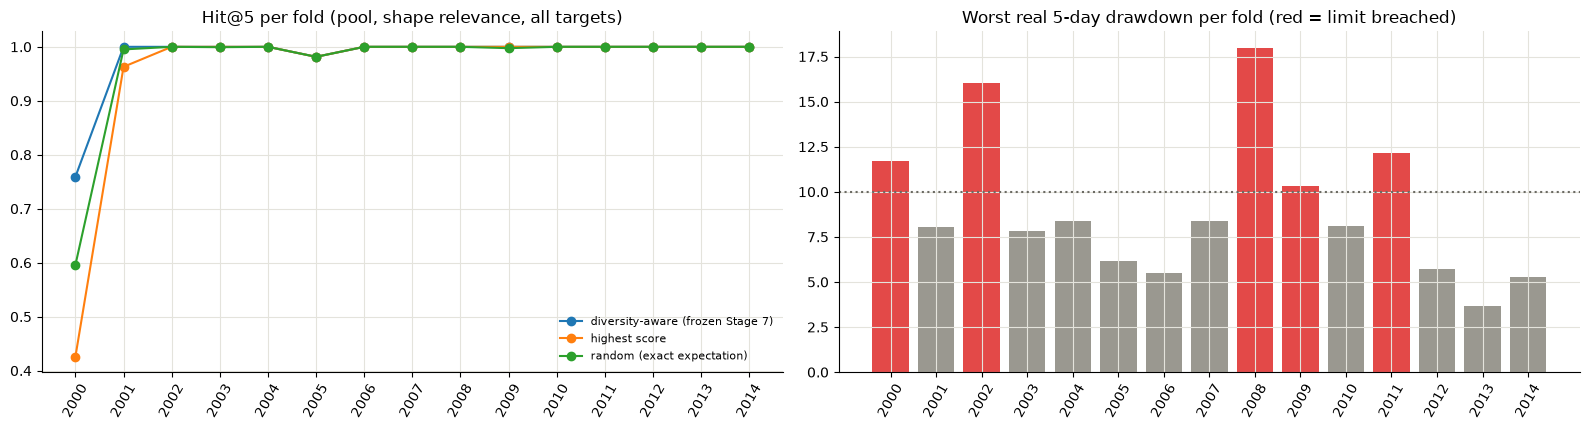

check,result,detail
base protocol unchanged,PASS,42a256a49fa6
backcast protocol frozen before evaluation and unchanged,PASS,63080817fcce
frozen artifacts unchanged,PASS,
every evaluated week starts inside a declared fold,PASS,
shortlists taken unchanged from the base protocol,PASS,
backcast period strictly before project data,PASS,"('2000-01-03', '2014-12-24')"
downloaded after the protocol freeze; files unchanged,PASS,


7/7 checks PASS | wrote results/stage7_2/backcast_2000_2014/backcast_results.json


In [5]:
# 12d. Figure, save and checks
per = BC["per_portfolio_fold"]
sub = per[(per["targets"] == "all targets") & (per["relevance"] == "shape") & (per["catalog"] == "Stage 7.2 pool")]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.4))
for rname in ["diversity-aware (frozen Stage 7)", "highest score", "random (exact expectation)"]:
    s = sub[sub["recommender"] == rname].groupby("fold")["hit"].mean()
    axes[0].plot(s.index, s.values, marker="o", label=rname)
axes[0].set_title("Hit@5 per fold (pool, shape relevance, all targets)"); axes[0].legend(frameon=False, fontsize=8); axes[0].tick_params(axis="x", rotation=60)
h = BC["historical"]; axes[1].bar(h["fold"], h["worst 5-day drawdown"] * 100, color=np.where(h["breach episodes"] > 0, "#e34948", "#9a9890"))
axes[1].axhline(dd_limit * 100, color="#6b6a63", ls=":"); axes[1].set_title("Worst real 5-day drawdown per fold (red = limit breached)"); axes[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

bc_checks = []
def bcheck(name, ok, detail=""):
    bc_checks.append({"check": name, "result": "PASS" if ok else "FAIL", "detail": detail})
bcheck("base protocol unchanged", hashlib.sha256(PROTOCOL_PATH.read_text().encode()).hexdigest() == BASE_SHA, BASE_SHA[:12])
bcheck("backcast protocol frozen before evaluation and unchanged", BC_PROTOCOL.read_text() == bc_text, BC_SHA[:12])
bcheck("frozen artifacts unchanged", {p: sha(p) for p in FROZEN} == SHA_BEFORE)
bcheck("every evaluated week starts inside a declared fold", BC["per_portfolio_fold"]["fold"].isin((DRY_FOLDS if BC_DRY_RUN else BC_FOLDS).keys()).all())
bcheck("shortlists taken unchanged from the base protocol", all(len(PROTO["shortlists"][c][r][p]) == K5 for c in PROTO["shortlists"] for r in PROTO["shortlists"][c] for p in PROTO["portfolios"]))
if not BC_DRY_RUN:
    bcheck("backcast period strictly before project data", pd.Timestamp(BC["window_starts"][1]) < source.index.min(), str(BC["window_starts"]))
    bcheck("downloaded after the protocol freeze; files unchanged", pd.Timestamp(BC_MAN["downloaded_utc"]) > pd.Timestamp(bc_meta["written_utc"]))
bc_checks_df = pd.DataFrame(bc_checks)
display(bc_checks_df.style.hide(axis="index"))
assert (bc_checks_df["result"] == "PASS").all()
(BC_OUT / "reports").mkdir(parents=True, exist_ok=True)
bc_path = BC_OUT / "backcast_results.json"
if bc_path.exists() and not BC_DRY_RUN:
    raise FileExistsError(f"{bc_path} exists; the backcast is evaluated once")
bc_path.write_text(to_json({"schema": "stage7_2.backcast.v1", "mode": "dry run" if BC_DRY_RUN else "backcast", "generated_utc": pd.Timestamp.now(tz="UTC").isoformat(),
                            "base_protocol_sha256": BASE_SHA, "backcast_protocol_sha256": BC_SHA, "label": BC["label"], "window_starts": BC["window_starts"],
                            "historical": BC["historical"].to_dict("records"), "aggregate": BC["aggregate"].to_dict("records"), "checks": bc_checks}))
BC["per_portfolio_fold"].to_csv(BC_OUT / "reports" / "per_portfolio_fold.csv", index=False)
BC["aggregate"].to_csv(BC_OUT / "reports" / "aggregate.csv", index=False)
BC["historical"].to_csv(BC_OUT / "reports" / "folds.csv", index=False)
print(f"{len(bc_checks_df)}/{len(bc_checks_df)} checks PASS | wrote {bc_path.relative_to(PROJECT_ROOT)}")

### 12e. Limitations of the backcast
- **It is a backcast.** The frozen model and the scenario library were built from 2015–2021 data, so they "know" later
  market behaviour, although they never saw 2000–2014.
- **The portfolio was chosen with hindsight.** The 8 stocks were picked in 2015 knowing they survived and grew.
  Market structure in 2000–2014 also differs (for example the dot-com era and the 2008 financial crisis).
- **The shape rule is new.** It is looser and scale-free. It was frozen before the 2000–2014 download, but after the
  zero results of 2022/2023/2026 were seen, so read it as a secondary, more lenient view, with *strict* as the primary.
- **Folds overlap in the portfolios** (the same weeks are seen by 54 portfolios). The block bootstrap only partly
  accounts for this.